## *Clustering Karakter Genshin Impact Berdasarkan Atribut Karakter dan Statistik Penggunaan Menggunakan Algoritma K-Means*

### Import Library

In [1]:
import ast
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

### Import Dataset

In [2]:
DATA_PATH = "/content/drive/MyDrive/Genshin Impact Dataset/genshin_impact.csv"  # Ubah sesuai lokasi file CSV

if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH}. "
        "Letakkan CSV di folder notebook atau ubah DATA_PATH ke lokasi yang benar."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df_raw.shape)
display(df_raw.head())

Ukuran dataset: (103, 32)


,Unnamed: 0,name,rarity,weapon,element,3D-model,region,release_date,days_since_release,banner_versions,banner_dates,roles,constellation_0_pull,constellation_1_pull,constellation_2_pull,constellation_3_pull,constellation_4_pull,constellation_5_pull,constellation_6_pull,constellation_7_pull,asc_stat_bonus_category,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,num_banners,months_since_release,is_standard_banner,is_archon,pulled_count
0,0,lynette,4,Sword,Anemo,Medium Female,Fontaine,2023-08-16,872,"['4.0', '4.6', '5.6']","['August 16, 2023 – September 5, 2023', 'April 24, 2024 – May 14, 2024', 'May 27, 2025 – June 17...","Off-Field,DPS",301409,240308,198054,149152,100295,81006,48706,219453,Anemo DMG Bonus,12397,232,712,0.774796,0.036392,4.440421,3,28.590164,1,0,1338383
1,1,varesa,5,Catalyst,Electro,Medium Female,Natlan,2025-03-26,284,"['5.5', 'Luna III']","['March 26, 2025 – April 15, 2025', 'December 23, 2025 – January 13, 2026']","On-Field,DPS",69219,11980,6303,1140,575,390,3353,90,CRIT Rate,12699,356,782,0.256102,0.036035,1.344270,2,9.311475,0,0,93049
2,2,chongyun,4,Claymore,Cryo,Medium Male,Liyue,2020-09-28,1924,"['1.1', '1.3', '2.0', '2.2', '2.4', '2.7', '3.7', '4.1', '5.4', '5.3']","['December 1, 2020 – December 22, 2020', 'March 2, 2021 – March 16, 2021', 'July 21, 2021 – Augu...","Off-Field,DPS,Support",1330794,971436,690870,433896,259920,158592,98847,332967,ATK%,10984,223,648,0.688872,0.023110,3.214113,10,63.081967,1,0,4277322
3,3,tighnari,5,Bow,Dendro,Medium Male,Sumeru,2022-08-24,1229,"['3.0', 'Luna I']","['August 24, 2022 – September 9, 2022', 'September 10, 2025 – September 30, 2025']","On-Field,DPS",681601,30666,3741,588,200,108,959,90,Dendro DMG Bonus,10850,268,630,0.050633,0.001336,1.053333,2,40.295082,1,0,717953
4,4,jean,5,Sword,Anemo,Tall Female,Mondstadt,2020-09-28,1924,['4.5'],"['March 13, 2024 – April 2, 2024']","Off-Field,Survivability",1291930,44118,4584,572,65,36,42,66,Healing Bonus,14695,239,769,0.036889,0.000031,1.038302,1,63.081967,1,0,1341413


In [3]:
print("Nama kolom:")
print(df_raw.columns.tolist())

print("\nTipe data:")
display(df_raw.dtypes.astype(str).rename("dtype").to_frame())

print("\nJumlah nilai kosong per kolom:")
display(df_raw.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())

print("\nJumlah baris duplikat:", df_raw.duplicated().sum())
display(df_raw.describe(include="all").T)

Nama kolom:
['Unnamed: 0', 'name', 'rarity', 'weapon', 'element', '3D-model', 'region', 'release_date', 'days_since_release', 'banner_versions', 'banner_dates', 'roles', 'constellation_0_pull', 'constellation_1_pull', 'constellation_2_pull', 'constellation_3_pull', 'constellation_4_pull', 'constellation_5_pull', 'constellation_6_pull', 'constellation_7_pull', 'asc_stat_bonus_category', 'lvl_90_HP', 'lvl_90_ATK', 'lvl_90_DEF', 'duplicate_rate', 'c6_rate', 'avg_copies_per_player', 'num_banners', 'months_since_release', 'is_standard_banner', 'is_archon', 'pulled_count']

Tipe data:


,dtype
Unnamed: 0,int64
name,object
rarity,int64
weapon,object
element,object
3D-model,object
region,object
release_date,object
days_since_release,int64
banner_versions,object



Jumlah nilai kosong per kolom:


,missing_count
Unnamed: 0,0
name,0
rarity,0
weapon,0
element,0
3D-model,0
region,0
release_date,0
days_since_release,0
banner_versions,0



Jumlah baris duplikat: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,103.0,NaN,NaN,NaN,51.0,29.877528,0.0,25.5,51.0,76.5,102.0
name,103,103,lynette,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rarity,103.0,NaN,NaN,NaN,4.563107,0.498427,4.0,4.0,5.0,5.0,5.0
weapon,103,5,Catalyst,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
element,103,7,Electro,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3D-model,103,5,Medium Female,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,103,9,Liyue,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,103,64,2020-09-28,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_since_release,103.0,NaN,NaN,NaN,1136.970874,622.325516,32.0,578.0,1178.0,1751.5,1924.0
banner_versions,103,96,['4.5'],3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data Cleaning

In [4]:
df = df_raw.copy()

# Hapus kolom indeks yang bukan atribut karakter
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Rapikan teks nama karakter
if "name" not in df.columns:
    raise ValueError("Kolom 'name' tidak ditemukan. Periksa struktur CSV.")

df["name"] = df["name"].astype("string").str.strip()
df = df[df["name"].notna() & (df["name"] != "")].copy()

# Nama karakter diharapkan unik untuk analisis ini
duplicate_names = df["name"].duplicated().sum()
print("Duplikasi nama karakter:", duplicate_names)
if duplicate_names > 0:
    print("Ditemukan nama berulang; mempertahankan baris pertama per nama.")
    df = df.drop_duplicates(subset="name", keep="first").copy()

# Kolom numerik yang mungkin digunakan
numeric_candidates = [
    "rarity", "days_since_release", "num_banners",
    "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "months_since_release", "is_standard_banner", "is_archon",
    "pulled_count"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Ukuran setelah pembersihan:", df.shape)
display(df.head())

Duplikasi nama karakter: 0
Ukuran setelah pembersihan: (103, 31)


,name,rarity,weapon,element,3D-model,region,release_date,days_since_release,banner_versions,banner_dates,roles,constellation_0_pull,constellation_1_pull,constellation_2_pull,constellation_3_pull,constellation_4_pull,constellation_5_pull,constellation_6_pull,constellation_7_pull,asc_stat_bonus_category,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,num_banners,months_since_release,is_standard_banner,is_archon,pulled_count
0,lynette,4,Sword,Anemo,Medium Female,Fontaine,2023-08-16,872,"['4.0', '4.6', '5.6']","['August 16, 2023 – September 5, 2023', 'April 24, 2024 – May 14, 2024', 'May 27, 2025 – June 17...","Off-Field,DPS",301409,240308,198054,149152,100295,81006,48706,219453,Anemo DMG Bonus,12397,232,712,0.774796,0.036392,4.440421,3,28.590164,1,0,1338383
1,varesa,5,Catalyst,Electro,Medium Female,Natlan,2025-03-26,284,"['5.5', 'Luna III']","['March 26, 2025 – April 15, 2025', 'December 23, 2025 – January 13, 2026']","On-Field,DPS",69219,11980,6303,1140,575,390,3353,90,CRIT Rate,12699,356,782,0.256102,0.036035,1.344270,2,9.311475,0,0,93049
2,chongyun,4,Claymore,Cryo,Medium Male,Liyue,2020-09-28,1924,"['1.1', '1.3', '2.0', '2.2', '2.4', '2.7', '3.7', '4.1', '5.4', '5.3']","['December 1, 2020 – December 22, 2020', 'March 2, 2021 – March 16, 2021', 'July 21, 2021 – Augu...","Off-Field,DPS,Support",1330794,971436,690870,433896,259920,158592,98847,332967,ATK%,10984,223,648,0.688872,0.023110,3.214113,10,63.081967,1,0,4277322
3,tighnari,5,Bow,Dendro,Medium Male,Sumeru,2022-08-24,1229,"['3.0', 'Luna I']","['August 24, 2022 – September 9, 2022', 'September 10, 2025 – September 30, 2025']","On-Field,DPS",681601,30666,3741,588,200,108,959,90,Dendro DMG Bonus,10850,268,630,0.050633,0.001336,1.053333,2,40.295082,1,0,717953
4,jean,5,Sword,Anemo,Tall Female,Mondstadt,2020-09-28,1924,['4.5'],"['March 13, 2024 – April 2, 2024']","Off-Field,Survivability",1291930,44118,4584,572,65,36,42,66,Healing Bonus,14695,239,769,0.036889,0.000031,1.038302,1,63.081967,1,0,1341413


### Exploratory Data Analysis (EDA)

In [5]:
# Pastikan kolom yang akan diplot tersedia
eda_cols = [c for c in [
    "rarity", "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "num_banners", "pulled_count"
] if c in df.columns]

display(df[eda_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
rarity,103.0,4.563107e+00,4.984270e-01,4.000000,4.000000,5.000000,5.000000e+00,5.000000e+00
lvl_90_HP,103.0,1.190508e+04,1.621564e+03,9189.000000,10470.000000,12289.000000,1.296850e+04,1.567500e+04
lvl_90_ATK,103.0,2.597864e+02,6.058209e+01,106.000000,213.500000,244.000000,3.205000e+02,3.590000e+02
lvl_90_DEF,103.0,7.047573e+02,1.034497e+02,500.000000,615.000000,712.000000,7.840000e+02,9.590000e+02
duplicate_rate,103.0,4.420790e-01,2.828935e-01,0.036889,0.193033,0.338379,7.444530e-01,8.745344e-01
c6_rate,103.0,3.376932e-02,2.085229e-02,0.000016,0.023742,0.033027,4.215371e-02,1.378546e-01
avg_copies_per_player,103.0,2.542524e+00,1.612235e+00,1.038302,1.239312,1.511439,3.913222e+00,7.970314e+00
num_banners,103.0,4.834951e+00,3.486942e+00,1.000000,2.000000,4.000000,6.000000e+00,1.600000e+01
pulled_count,103.0,1.562093e+06,1.921422e+06,16854.000000,224798.000000,652085.000000,2.261590e+06,7.659164e+06


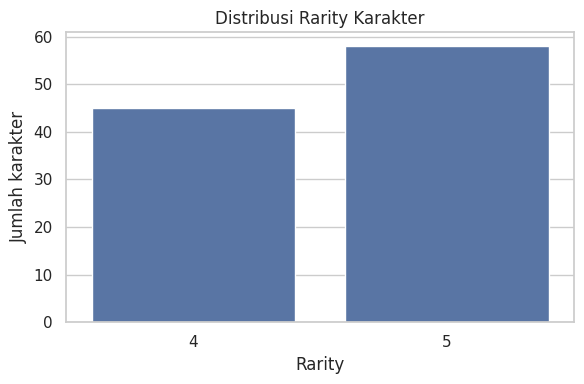

In [6]:
if "rarity" in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="rarity")
    plt.title("Distribusi Rarity Karakter")
    plt.xlabel("Rarity")
    plt.ylabel("Jumlah karakter")
    plt.tight_layout()
    plt.show()

plot_cols = [c for c in [
    "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "num_banners", "pulled_count"
] if c in df.columns]

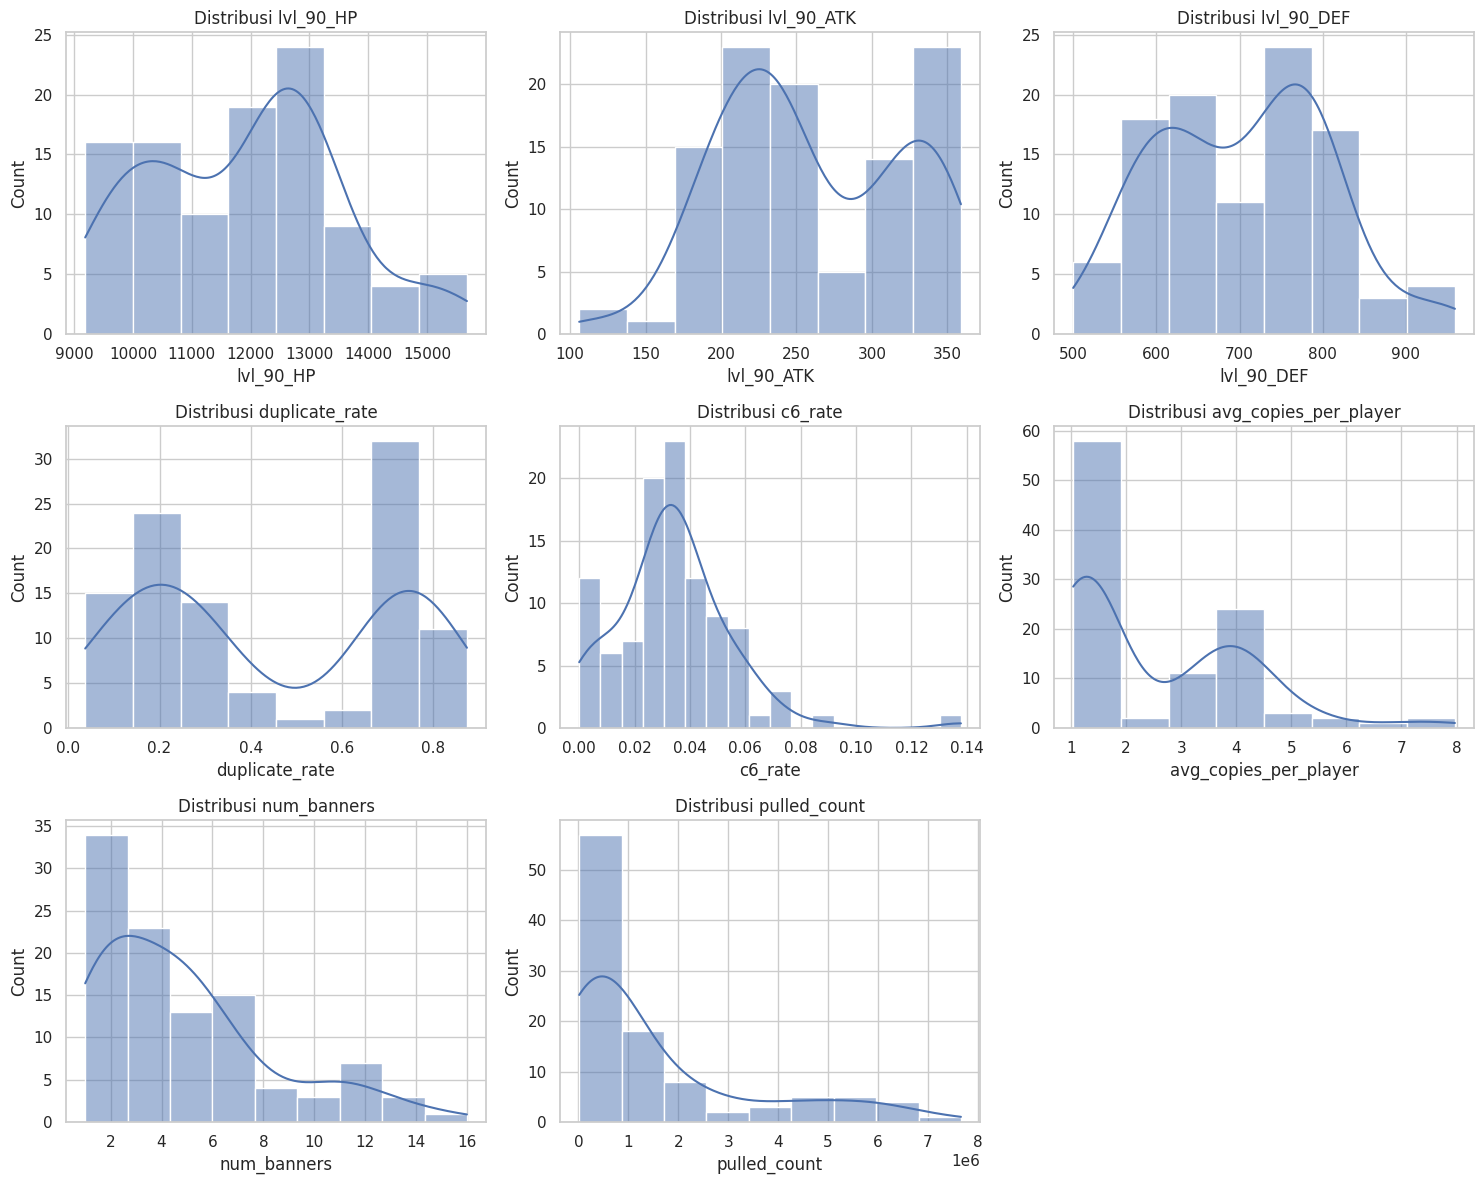

In [7]:
if plot_cols:
    ncols = 3
    nrows = int(np.ceil(len(plot_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, plot_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"Distribusi {col}")
    for ax in axes[len(plot_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

corr_cols = [c for c in [
    "rarity", "days_since_release", "num_banners",
    "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "months_since_release", "pulled_count"
] if c in df.columns]

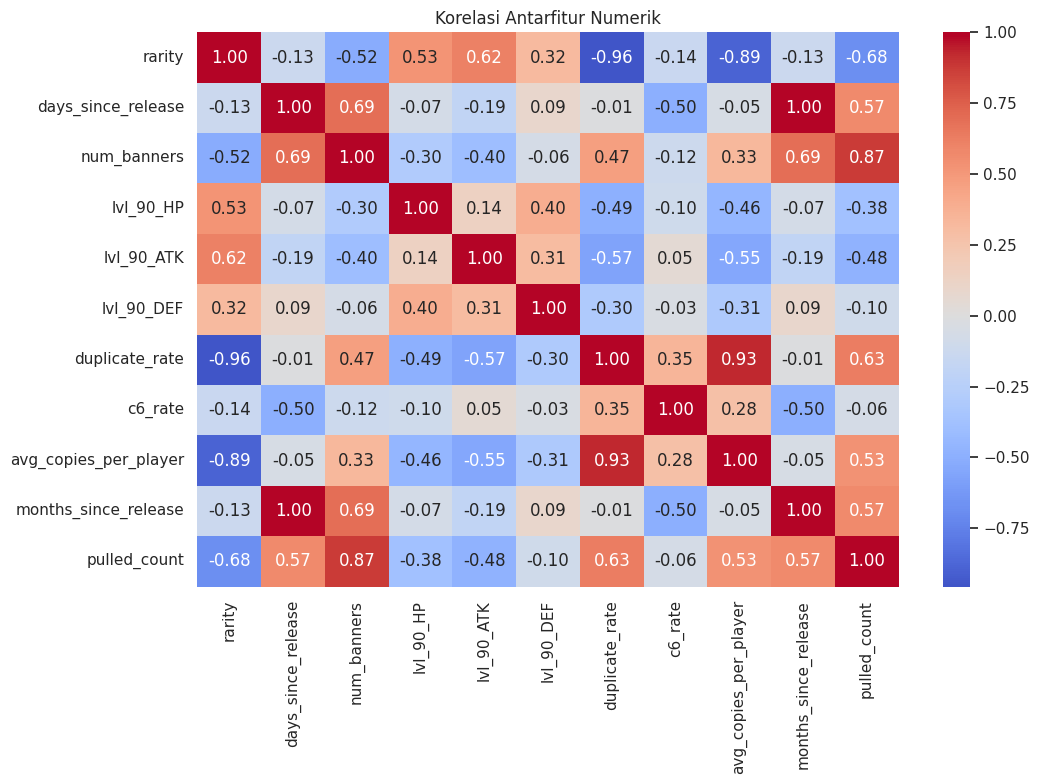

In [8]:
if len(corr_cols) >= 2:
    plt.figure(figsize=(11, 8))
    sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Korelasi Antarfitur Numerik")
    plt.tight_layout()
    plt.show()

In [9]:
# Pilihan fitur numerik
numeric_features = [
    "rarity",
    "days_since_release",
    "num_banners",
    "lvl_90_HP",
    "lvl_90_ATK",
    "lvl_90_DEF",
    "duplicate_rate",
    "c6_rate",
    "avg_copies_per_player",
    "pulled_count",
    "is_standard_banner",
    "is_archon",
]
numeric_features = [c for c in numeric_features if c in df.columns]

In [10]:
# Pilihan fitur kategorikal
categorical_features = [
    "weapon",
    "element",
    "region",
    "asc_stat_bonus_category",
]
categorical_features = [c for c in categorical_features if c in df.columns]

In [11]:
# roles diperlakukan sebagai multi-label: misalnya "Off-Field,DPS,Support"
use_roles = "roles" in df.columns

In [12]:
# Hilangkan fitur yang seluruh nilainya kosong atau hanya satu nilai unik
numeric_features = [
    c for c in numeric_features
    if df[c].notna().any() and df[c].nunique(dropna=True) > 1
]
categorical_features = [
    c for c in categorical_features
    if df[c].notna().any() and df[c].nunique(dropna=True) > 1
]

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
print("Menggunakan roles multi-label:", use_roles)
print("Jumlah karakter:", len(df))

Fitur numerik: ['rarity', 'days_since_release', 'num_banners', 'lvl_90_HP', 'lvl_90_ATK', 'lvl_90_DEF', 'duplicate_rate', 'c6_rate', 'avg_copies_per_player', 'pulled_count', 'is_standard_banner', 'is_archon']
Fitur kategorikal: ['weapon', 'element', 'region', 'asc_stat_bonus_category']
Menggunakan roles multi-label: True
Jumlah karakter: 103


### Preprocessing Data

In [13]:
# Salinan data fitur
X_num = df[numeric_features].copy()
X_cat = df[categorical_features].copy()

# Transformasi untuk mengurangi skew pada hitungan pull
if "pulled_count" in X_num.columns:
    X_num["pulled_count"] = np.log1p(X_num["pulled_count"].clip(lower=0))

In [14]:
# Pastikan indikator numerik tetap diperlakukan sebagai numerik
# Nilai kosong diisi median pada fitur numerik
for col in X_num.columns:
    X_num[col] = X_num[col].replace([np.inf, -np.inf], np.nan)
    X_num[col] = X_num[col].fillna(X_num[col].median())

# Isi nilai kategorikal kosong dengan label eksplisit
for col in X_cat.columns:
    X_cat[col] = X_cat[col].astype("string").fillna("Unknown").astype(str)

In [15]:
# Scaling numerik
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num) if len(numeric_features) else np.empty((len(df), 0))

In [16]:
# One-hot encoding kategori (kompatibel dengan beberapa versi scikit-learn)
if len(categorical_features):
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    X_cat_encoded = encoder.fit_transform(X_cat)
    cat_feature_names = encoder.get_feature_names_out(categorical_features).tolist()
else:
    X_cat_encoded = np.empty((len(df), 0))
    cat_feature_names = []

In [17]:
# Multi-label encoding untuk roles
if use_roles:
    roles_clean = (
        df["roles"].fillna("").astype(str)
        .apply(lambda x: [part.strip() for part in x.split(",") if part.strip()])
        .tolist()
    )
    mlb = MultiLabelBinarizer()
    X_roles_encoded = mlb.fit_transform(roles_clean)
    role_feature_names = [f"role_{x}" for x in mlb.classes_]
else:
    X_roles_encoded = np.empty((len(df), 0))
    role_feature_names = []

In [18]:
# Gabungkan seluruh fitur yang telah diproses
X = np.hstack([X_num_scaled, X_cat_encoded, X_roles_encoded]).astype(float)
feature_names = list(numeric_features) + cat_feature_names + role_feature_names

print("Matriks fitur akhir:", X.shape)
print("Jumlah fitur setelah encoding:", len(feature_names))
print("Contoh nama fitur:", feature_names[:20])

if X.shape[1] == 0:
    raise ValueError("Tidak ada fitur yang dapat digunakan untuk clustering.")
if len(df) < 3:
    raise ValueError("Jumlah baris terlalu sedikit untuk mengevaluasi clustering.")

Matriks fitur akhir: (103, 54)
Jumlah fitur setelah encoding: 54
Contoh nama fitur: ['rarity', 'days_since_release', 'num_banners', 'lvl_90_HP', 'lvl_90_ATK', 'lvl_90_DEF', 'duplicate_rate', 'c6_rate', 'avg_copies_per_player', 'pulled_count', 'is_standard_banner', 'is_archon', 'weapon_Bow', 'weapon_Catalyst', 'weapon_Claymore', 'weapon_Polearm', 'weapon_Sword', 'element_Anemo', 'element_Cryo', 'element_Dendro']


In [19]:
max_k = min(10, len(df) - 1)
k_values = list(range(2, max_k + 1))

evaluation_rows = []
models = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X)
    models[k] = model

    evaluation_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "smallest_cluster": pd.Series(labels).value_counts().min(),
        "largest_cluster": pd.Series(labels).value_counts().max(),
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster,largest_cluster
0,2,1158.4483,0.2885,1.3917,47.4898,45,58
1,3,1048.0913,0.2958,1.3931,31.2499,6,52
2,4,948.4678,0.2171,1.5794,26.2575,6,52
3,5,854.2860,0.1630,1.8256,24.3444,6,32
4,6,795.3500,0.1640,1.7832,22.1427,6,23
5,7,746.0370,0.1723,1.6256,20.5268,6,26
6,8,710.2698,0.1700,1.6282,18.9713,6,24
7,9,692.4865,0.1438,1.7703,17.1487,6,19
8,10,665.5090,0.1478,1.7166,16.1113,6,18


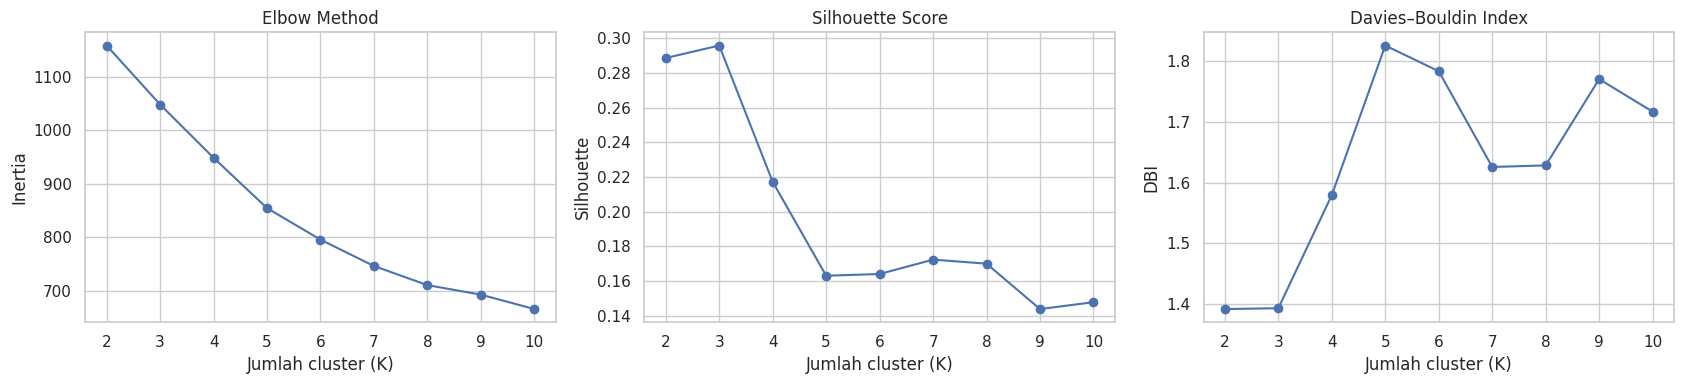

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(evaluation_df["k"], evaluation_df["inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah cluster (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(evaluation_df["k"], evaluation_df["silhouette"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah cluster (K)")
axes[1].set_ylabel("Silhouette")

axes[2].plot(evaluation_df["k"], evaluation_df["davies_bouldin"], marker="o")
axes[2].set_title("Davies–Bouldin Index")
axes[2].set_xlabel("Jumlah cluster (K)")
axes[2].set_ylabel("DBI")

plt.tight_layout()
plt.show()

In [21]:
# Kandidat otomatis: K dengan Silhouette tertinggi.
# Tetap tinjau grafik dan ukuran cluster sebelum menetapkan K final.
best_k_silhouette = int(evaluation_df.loc[evaluation_df["silhouette"].idxmax(), "k"])
print("K dengan Silhouette Score tertinggi:", best_k_silhouette)
print("Catatan: pilihan otomatis ini adalah kandidat awal, bukan keputusan final.")

K dengan Silhouette Score tertinggi: 3
Catatan: pilihan otomatis ini adalah kandidat awal, bukan keputusan final.


### Menetapkan Model Akhir

In [23]:
FINAL_K = best_k_silhouette  # Ubah manual setelah meninjau hasil evaluasi

if FINAL_K not in k_values:
    raise ValueError(f"FINAL_K harus salah satu dari {k_values}")

final_model = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=20)
cluster_labels = final_model.fit_predict(X)

In [24]:
results = df.copy()
results["cluster"] = cluster_labels

print("K final:", FINAL_K)
print("Silhouette Score:", round(silhouette_score(X, cluster_labels), 4))
print("Davies–Bouldin Index:", round(davies_bouldin_score(X, cluster_labels), 4))
print("Calinski–Harabasz Score:", round(calinski_harabasz_score(X, cluster_labels), 4))
print("\nJumlah karakter per cluster:")
display(results["cluster"].value_counts().sort_index().rename("jumlah_karakter").to_frame())

K final: 3
Silhouette Score: 0.2958
Davies–Bouldin Index: 1.3931
Calinski–Harabasz Score: 31.2499

Jumlah karakter per cluster:


,jumlah_karakter
cluster,
0,6
1,45
2,52


### Cluster Visualization

In [26]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": cluster_labels,
    "name": results["name"].astype(str).values
})

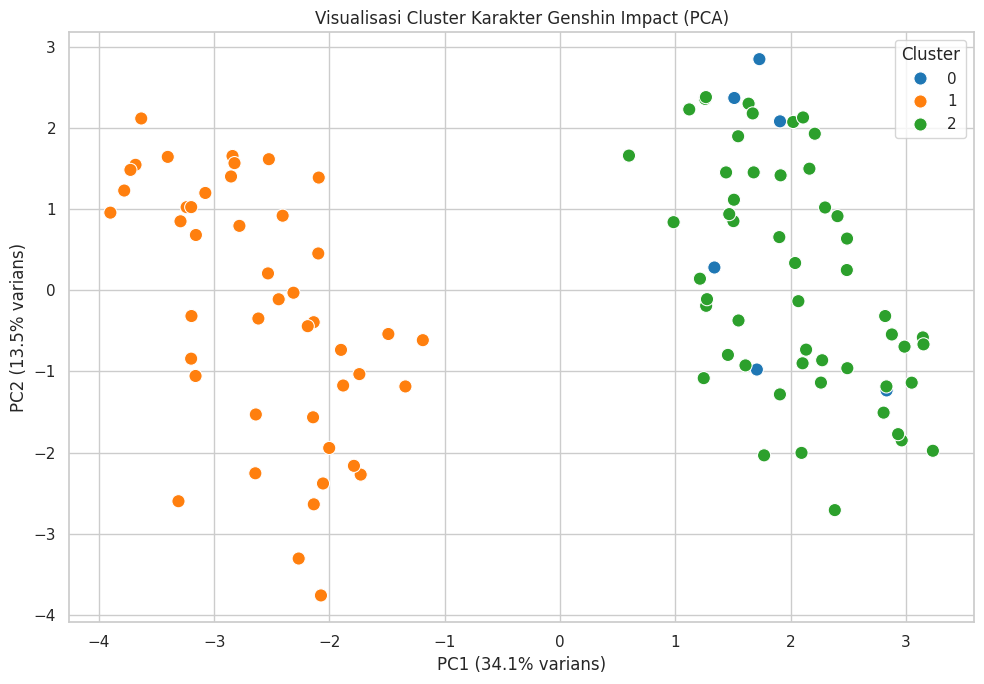

Total varians yang dijelaskan dua komponen PCA: 47.62%


In [27]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2",
    hue="cluster", palette="tab10", s=90
)
plt.title("Visualisasi Cluster Karakter Genshin Impact (PCA)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("Total varians yang dijelaskan dua komponen PCA:",
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")

In [28]:
profile_numeric = [c for c in [
    "rarity", "days_since_release", "num_banners",
    "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "pulled_count", "is_standard_banner", "is_archon"
] if c in results.columns]

cluster_means = results.groupby("cluster")[profile_numeric].mean().round(3)
cluster_medians = results.groupby("cluster")[profile_numeric].median().round(3)

print("Rata-rata fitur numerik per cluster:")
display(cluster_means)

print("Median fitur numerik per cluster:")
display(cluster_medians)

Rata-rata fitur numerik per cluster:


,rarity,days_since_release,num_banners,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,pulled_count,is_standard_banner,is_archon
cluster,,,,,,,,,,,,
0,5.0,1280.833,5.167,12725.333,292.167,719.000,0.270,0.038,1.414,639830.167,0.000,1.0
1,4.0,1225.756,6.867,10941.022,217.600,667.889,0.747,0.037,4.171,3046744.133,1.000,0.0
2,5.0,1043.538,3.038,12644.712,292.558,735.019,0.198,0.030,1.264,383714.019,0.154,0.0


Median fitur numerik per cluster:


,rarity,days_since_release,num_banners,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,pulled_count,is_standard_banner,is_archon
cluster,,,,,,,,,,,,
0,5.0,1372.5,5.5,12729.5,281.0,717.0,0.309,0.028,1.447,660655.0,0.0,1.0
1,4.0,1229.0,6.0,10875.0,223.0,669.0,0.749,0.035,3.989,2542518.0,1.0,0.0
2,5.0,1061.0,3.0,12858.0,315.5,767.0,0.201,0.028,1.252,232909.0,0.0,0.0


In [29]:
print("Contoh karakter per cluster:")
for cluster_id in sorted(results["cluster"].unique()):
    subset = results.loc[results["cluster"] == cluster_id, "name"].astype(str).tolist()
    print(f"Cluster {cluster_id} ({len(subset)} karakter): {', '.join(subset[:25])}" +
          (" ..." if len(subset) > 25 else ""))

Contoh karakter per cluster:
Cluster 0 (6 karakter): venti, zhongli, furina, nahida, mavuika, raiden_shogun
Cluster 1 (45 karakter): lynette, chongyun, gorou, layla, iansan, gaming, noelle, shikanoin_heizou, collei, kujou_sara, chevreuse, yun_jin, freminet, diona, mika, xingqiu, kirara, kuki_shinobu, bennett, kachina, candace, xinyan, faruzan, yanfei, dahlia ...
Cluster 2 (52 karakter): varesa, tighnari, jean, keqing, mona, dehya, qiqi, diluc, xilonen, durin, arlecchino, nefer, flins, yelan, lauma, chasca, mualani, citlali, ineffa, emilie, shenhe, skirk, kinich, escoffier, navia ...


In [30]:
# Distribusi kategori per cluster (jika kolom tersedia)
for col in [c for c in ["rarity", "weapon", "element", "region", "is_archon", "is_standard_banner"] if c in results.columns]:
    print(f"\nDistribusi {col} dalam setiap cluster (proporsi per cluster):")
    display(pd.crosstab(results["cluster"], results[col], normalize="index").round(3))


Distribusi rarity dalam setiap cluster (proporsi per cluster):


rarity,4,5
cluster,,
0,0.0,1.0
1,1.0,0.0
2,0.0,1.0



Distribusi weapon dalam setiap cluster (proporsi per cluster):


weapon,Bow,Catalyst,Claymore,Polearm,Sword
cluster,,,,,
0,0.167,0.167,0.167,0.333,0.167
1,0.200,0.178,0.244,0.222,0.156
2,0.154,0.288,0.115,0.173,0.269



Distribusi element dalam setiap cluster (proporsi per cluster):


...

region,Extra-Terresterial,Fontaine,Inazuma,Liyue,Mondstadt,Natlan,Nod-Krai,Snezhnaya,Sumeru
cluster,,,,,,,,,
0,0.000,0.167,0.167,0.167,0.167,0.167,0.000,0.000,0.167
1,0.000,0.089,0.156,0.244,0.222,0.089,0.044,0.000,0.156
2,0.019,0.154,0.173,0.173,0.135,0.115,0.077,0.038,0.115



Distribusi is_archon dalam setiap cluster (proporsi per cluster):


is_archon,0,1
cluster,,
0,0.0,1.0
1,1.0,0.0
2,1.0,0.0



Distribusi is_standard_banner dalam setiap cluster (proporsi per cluster):


is_standard_banner,0,1
cluster,,
0,1.000,0.000
1,0.000,1.000
2,0.846,0.154


### Memeriksa fitur pembeda cluster

In [31]:
# X_num_scaled hanya memuat fitur numerik setelah transformasi log dan standardisasi
scaled_num_df = pd.DataFrame(X_num_scaled, columns=numeric_features, index=results.index)
scaled_num_df["cluster"] = cluster_labels

standardized_profile = scaled_num_df.groupby("cluster")[numeric_features].mean().round(2)
display(standardized_profile)

,rarity,days_since_release,num_banners,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,pulled_count,is_standard_banner,is_archon
cluster,,,,,,,,,,,,
0,0.88,0.23,0.10,0.51,0.54,0.14,-0.61,0.21,-0.70,-0.13,-1.03,4.02
1,-1.14,0.14,0.59,-0.60,-0.70,-0.36,1.08,0.16,1.01,0.85,0.97,-0.25
2,0.88,-0.15,-0.52,0.46,0.54,0.29,-0.87,-0.16,-0.80,-0.72,-0.72,-0.25


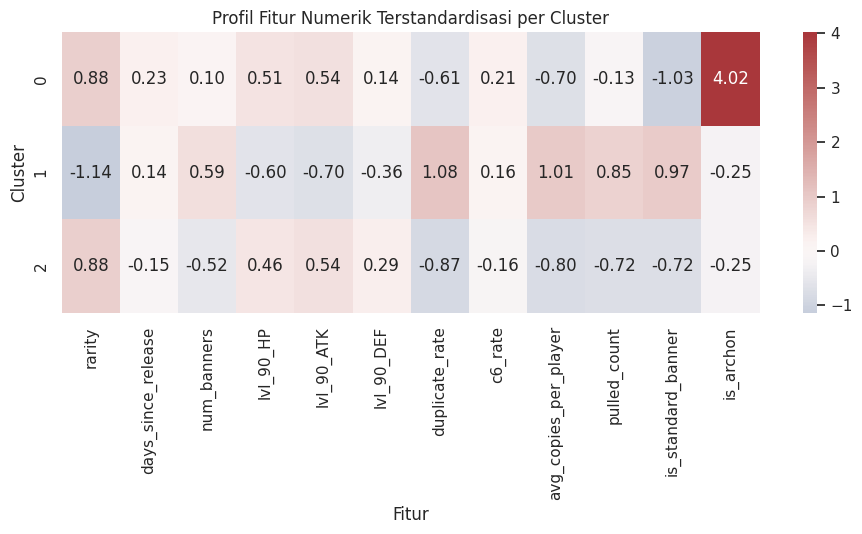

In [32]:
plt.figure(figsize=(max(9, len(numeric_features) * 0.8), 4 + FINAL_K * 0.5))
sns.heatmap(standardized_profile, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Profil Fitur Numerik Terstandardisasi per Cluster")
plt.xlabel("Fitur")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### Meninjau hasil per karakter

In [33]:
display_cols = [c for c in [
    "name", "cluster", "rarity", "weapon", "element", "region", "roles",
    "lvl_90_HP", "lvl_90_ATK", "lvl_90_DEF",
    "duplicate_rate", "c6_rate", "avg_copies_per_player",
    "num_banners", "pulled_count"
] if c in results.columns]

display(results[display_cols].sort_values(["cluster", "name"]).reset_index(drop=True))


,name,cluster,rarity,weapon,element,region,roles,lvl_90_HP,lvl_90_ATK,lvl_90_DEF,duplicate_rate,c6_rate,avg_copies_per_player,num_banners,pulled_count
0,furina,0,5,Sword,Hydro,Fontaine,"Off-Field,DPS,Support,Survivability",15307,244,696,0.458989,0.089735,1.848392,4,669225
1,mavuika,0,5,Claymore,Pyro,Natlan,"On-Field,Off-Field,DPS,Support",12552,359,792,0.321682,0.074273,1.474234,2,309884
2,nahida,0,5,Catalyst,Dendro,Sumeru,"Off-Field,DPS,Support",10360,299,630,0.295747,0.038613,1.419944,5,652085
3,raiden_shogun,0,5,Polearm,Electro,Inazuma,"On-Field,DPS,Support",12907,337,789,0.338379,0.016689,1.511439,6,1221840
4,venti,0,5,Bow,Anemo,Mondstadt,"Off-Field,DPS,Support",10531,263,669,0.065271,0.003183,1.069829,7,290312
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,xilonen,2,5,Sword,Geo,Natlan,"Off-Field,Support,Survivability",12405,275,930,0.286190,0.027048,1.400934,3,285712
99,yae_miko,2,5,Catalyst,Electro,Inazuma,"Off-Field,DPS",10372,340,569,0.236209,0.045976,1.309260,5,493600
100,yelan,2,5,Bow,Hydro,Liyue,"Off-Field,DPS",14450,244,548,0.274404,0.047290,1.378177,5,629547
101,yoimiya,2,5,Bow,Pyro,Inazuma,"On-Field,DPS",10164,323,615,0.167569,0.020289,1.201301,6,373643


In [34]:
OUTPUT_RESULTS = "genshin_character_clusters.csv"
OUTPUT_EVALUATION = "genshin_kmeans_evaluation.csv"

results.to_csv(OUTPUT_RESULTS, index=False)
evaluation_df.to_csv(OUTPUT_EVALUATION, index=False)

print("Hasil clustering tersimpan:", OUTPUT_RESULTS)
print("Tabel evaluasi tersimpan:", OUTPUT_EVALUATION)

Hasil clustering tersimpan: genshin_character_clusters.csv
Tabel evaluasi tersimpan: genshin_kmeans_evaluation.csv
